## Configuration

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..") 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import cfg

cfg.ensure_dirs()
TARGET = cfg.TARGET_COL
ORDER = cfg.TARGET_CLASSES

## Préparation (split 80/20 stratifié)

In [6]:
from src.train import step_prepare


paths = step_prepare()
train = pd.read_csv(paths["train"])
test = pd.read_csv(paths["test"])

print(train.shape, test.shape)

pd.DataFrame({
    "train": train[TARGET].value_counts(normalize=True),
    "test": test[TARGET].value_counts(normalize=True)}).reindex(ORDER).round(3)

2026-11-11 12:14:00,040 | INFO | src.data_loader | Données chargées : 2000 lignes x 17 colonnes


2026-11-11 12:14:00,046 | INFO | src.data_loader | Fin du nettoyage : 2000 lignes x 16 colonnes (0 lignes supprimées au total)
2026-11-11 12:14:00,070 | INFO | src.train | Train : 1600 lignes | Test : 400 lignes


(1600, 16) (400, 16)


,train,test
Mental_Health_Risk,,
Low,0.33,0.33
Medium,0.33,0.33
High,0.34,0.34


##  Entraînement, comparaison et optimisation

- 3 modèles + une baseline, même pipeline, même jeu d'entraînement
- Validation croisée stratifiée (5 folds)
- `RandomizedSearchCV` sur les 2 meilleurs modèles
- Le meilleur pipeline complet est sauvegardé dans `models/`

In [ ]:
from src.train import step_train

model_path = step_train(paths["train"])

2026-11-11 14:01:22,375 | INFO | src.train | CV dummy_baseline       f1_macro = 0.169
2026-11-11 14:01:22,480 | INFO | src.train | CV logistic_regression  f1_macro = 0.748
2026-11-11 14:01:23,534 | INFO | src.train | CV random_forest        f1_macro = 0.672
2026-11-11 14:01:23,633 | INFO | src.train | CV decision_tree        f1_macro = 0.574
2026-11-11 14:01:24,623 | INFO | src.train | Tuning logistic_regression  best f1_macro = 0.752
2026-11-11 14:01:39,469 | INFO | src.train | Tuning random_forest        best f1_macro = 0.681
2026-11-11 14:01:39,480 | INFO | src.train | Modèle sauvegardé : /home/ouelaimar/Desktop/student-mh-risk-predictor/models/model_pipeline.joblib (logistic_regression)


In [13]:
cv = pd.read_csv(cfg.CV_RESULTS_PATH).set_index("model")
cv.round(3)

,fit_time_s,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std
model,,,,,,,,,
logistic_regression,0.10,0.749,0.021,0.749,0.023,0.748,0.021,0.748,0.022
random_forest,1.05,0.675,0.028,0.672,0.026,0.674,0.028,0.672,0.027
decision_tree,0.10,0.574,0.028,0.576,0.022,0.573,0.028,0.574,0.025
dummy_baseline,0.08,0.340,0.001,0.113,0.000,0.333,0.000,0.169,0.000


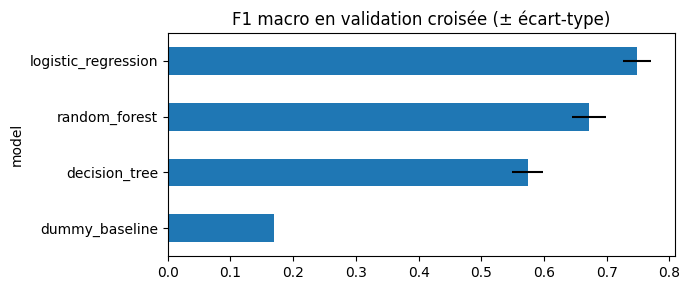

In [27]:
%matplotlib inline
ax = cv["f1_macro_mean"].sort_values().plot(kind="barh", xerr=cv["f1_macro_std"], figsize=(7, 3))
ax.set_title("F1 macro en validation croisée (± écart-type)")
plt.tight_layout()

plt.show()

In [23]:
import json

tuning = json.loads(cfg.TUNING_RESULTS_PATH.read_text())
pd.DataFrame({k: {"meilleur score CV": v["best_score"], "durée (s)": v["search_time_s"]}
              for k, v in tuning.items()}).T

,meilleur score CV,durée (s)
logistic_regression,0.751833,0.99
random_forest,0.681088,14.85


In [24]:
for name, res in tuning.items():
    print(name, res["best_params"])

logistic_regression {'model__C': 14.528246637516036, 'model__class_weight': 'balanced'}
random_forest {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 20}
